# Лабораторная работа №1. Регрессия качества вина

**Цель:** исследовать данные Wine Quality, сравнить baseline и три модели регрессии,
объяснить важность признаков и проанализировать ошибки.

Используем **красное вино**: `winequality-red.csv`. Цель `quality` — экспертная оценка
от 0 до 10. Предсказываем непрерывное число; основная метрика — **RMSE**, дополнительная — **MAE**.
Ориентир задания — RMSE < 0.70. Скрытая выборка преподавателя нам недоступна.

Источник: [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality).
Cortez et al. (2009), *Modeling wine preferences by data mining from physicochemical properties*,
[DOI: 10.1016/j.dss.2009.05.016](https://doi.org/10.1016/j.dss.2009.05.016).

Весь код и результаты находятся в этом ноутбуке. CSV должен лежать рядом.

## 1. Подготовка

Подключаем библиотеки. Во всех случайных разбиениях и моделях используем `random_state=42`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate, GridSearchCV
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

In [2]:
RANDOM_STATE = 42
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.2})

def show_plot():
    """Показать график внутри ноутбука, не создавая отдельный файл."""
    plt.tight_layout()
    plt.show()
    plt.close()

## 2. Загрузка и общий обзор датасета

Сначала знакомимся со **всей исходной таблицей**: размер, типы, пропуски, дубликаты,
распределения и наблюдаемые связи. Это описательный EDA; по результатам просмотра
тестовых ответов не выбираем признаки и параметры. Заранее сохраняем все 11 признаков.
Все обучаемые преобразования и подбор моделей далее выполняются только на train.

In [3]:
data = pd.read_csv('winequality-red.csv', sep=';')
print('Размер таблицы:', data.shape)
display(data.head())
data.info()

Размер таблицы: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


### 2.1. Качество данных

Числовые признаки описывают кислотность, сахар, хлориды, диоксид серы, плотность,
pH, сульфаты и содержание алкоголя. Проверим пропуски и повторяющиеся строки.

In [4]:
display(data.isna().sum().rename('missing').to_frame())
print('Полных дубликатов:', data.duplicated().sum())
assert data.shape[1] == 12
assert not data.isna().any().any()
assert np.isfinite(data.to_numpy()).all()
display(data.describe().T)

,missing
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Полных дубликатов: 240


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.3196,1.7411,4.6000,7.1000,7.9000,9.2000,15.9000
volatile acidity,1599.0,0.5278,0.1791,0.1200,0.3900,0.5200,0.6400,1.5800
citric acid,1599.0,0.2710,0.1948,0.0000,0.0900,0.2600,0.4200,1.0000
residual sugar,1599.0,2.5388,1.4099,0.9000,1.9000,2.2000,2.6000,15.5000
chlorides,1599.0,0.0875,0.0471,0.0120,0.0700,0.0790,0.0900,0.6110
free sulfur dioxide,1599.0,15.8749,10.4602,1.0000,7.0000,14.0000,21.0000,72.0000
total sulfur dioxide,1599.0,46.4678,32.8953,6.0000,22.0000,38.0000,62.0000,289.0000
density,1599.0,0.9967,0.0019,0.9901,0.9956,0.9968,0.9978,1.0037
pH,1599.0,3.3111,0.1544,2.7400,3.2100,3.3100,3.4000,4.0100
sulphates,1599.0,0.6581,0.1695,0.3300,0.5500,0.6200,0.7300,2.0000


**Вывод.** Пропусков нет, поэтому заполнение не требуется. Масштабы признаков различаются:
например, плотность близка к единице, а концентрация общего диоксида серы — десятки и сотни.
Для интерпретации линейных коэффициентов понадобится стандартизация.
Дубликаты не удаляем, но учтём их при разбиении, чтобы копии измерений не попали в обе части.

### 2.2. Распределение целевой переменной

В исходном описании `quality` — медиана не менее трёх экспертных оценок.
Проверим, какие оценки встречаются чаще, а какие представлены слабо.

,count
quality,
3,10
4,53
5,681
6,638
7,199
8,18


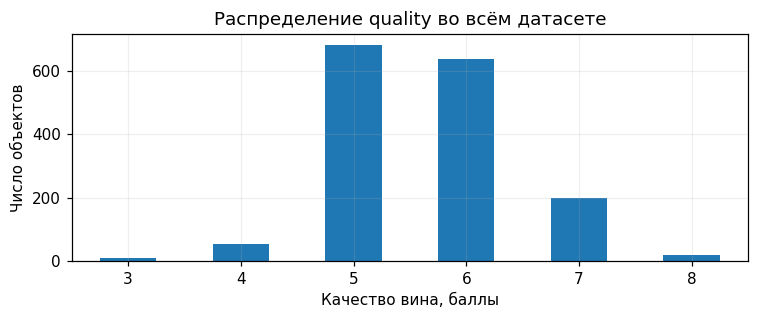

In [5]:
quality_counts = data['quality'].value_counts().sort_index()
display(quality_counts.rename('count').to_frame())
quality_counts.plot.bar(figsize=(7, 3), rot=0)
plt.xlabel('Качество вина, баллы')
plt.ylabel('Число объектов')
plt.title('Распределение quality во всём датасете')
show_plot()

**Вывод.** Основная масса оценок — 5 и 6; крайние оценки встречаются редко.
Модели будут получать гораздо меньше примеров низкого и высокого качества.
В анализе ошибок отдельно проверим такие группы. Редкие оценки не удаляем как «выбросы».

### 2.3. Распределения признаков

Гистограммы помогают увидеть асимметрию и необычные значения. Здесь не отбрасываем строки:
большие концентрации могут быть реальными измерениями, а не ошибками ввода.

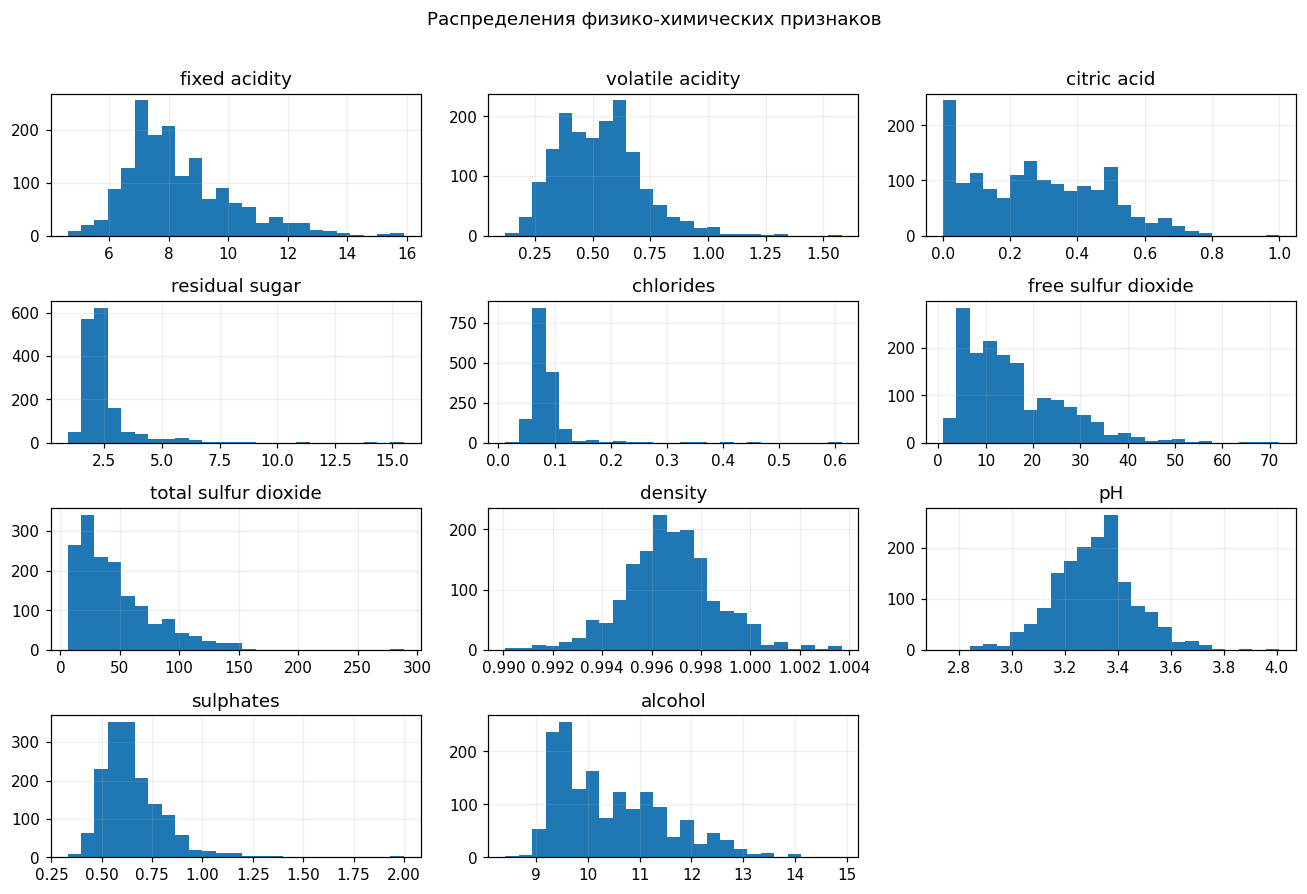

In [6]:
data.drop(columns='quality').hist(figsize=(12, 8), bins=25)
plt.suptitle('Распределения физико-химических признаков', y=1.01)
show_plot()

### 2.4. Корреляции

Корреляция Пирсона отражает отдельную линейную связь. Слабая корреляция не исключает
нелинейной зависимости или взаимодействия с другими признаками.

,correlation_with_quality
volatile acidity,-0.3906
total sulfur dioxide,-0.1851
density,-0.1749
chlorides,-0.1289
pH,-0.0577
free sulfur dioxide,-0.0507
residual sugar,0.0137
fixed acidity,0.1241
citric acid,0.2264
sulphates,0.2514


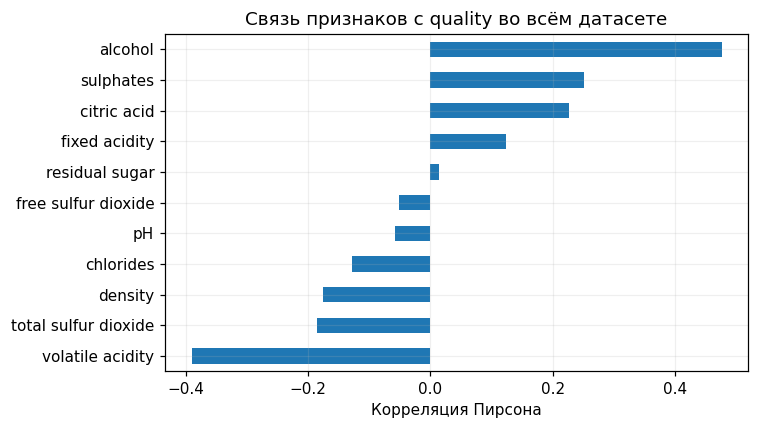

In [7]:
correlations = data.corr()
target_correlations = correlations['quality'].drop('quality').sort_values()
display(target_correlations.rename('correlation_with_quality').to_frame())
target_correlations.plot.barh(figsize=(7, 4))
plt.xlabel('Корреляция Пирсона')
plt.title('Связь признаков с quality во всём датасете')
show_plot()

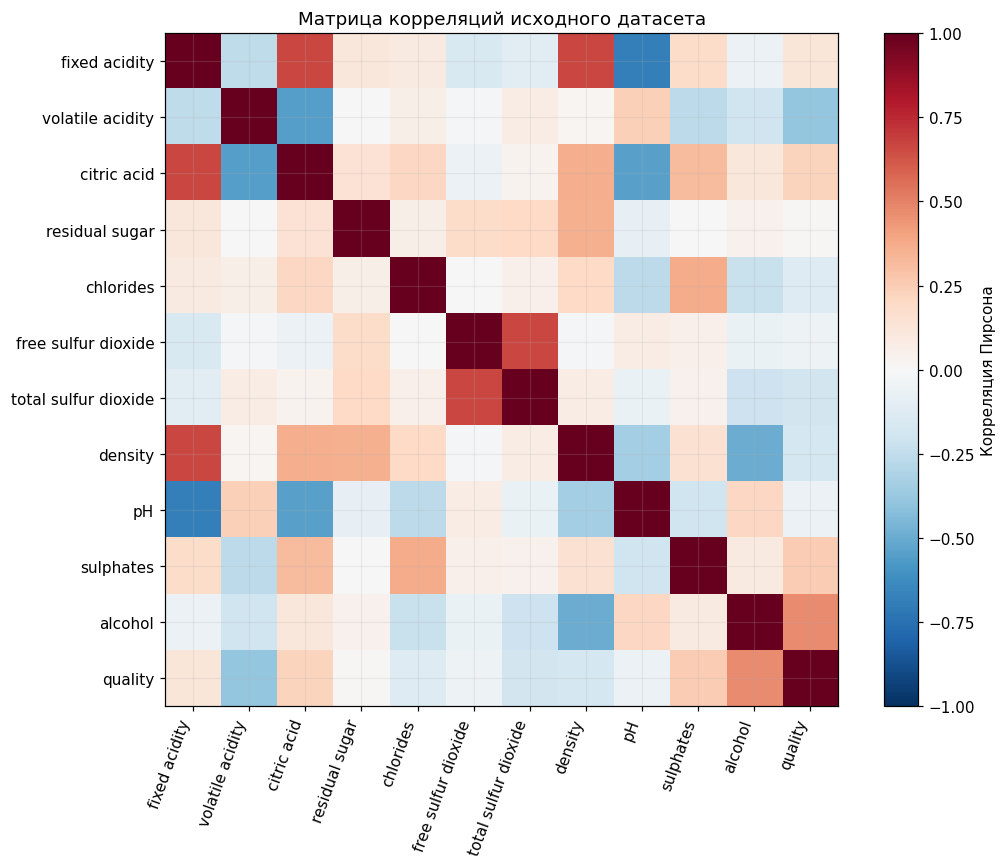

In [8]:
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(correlations, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(correlations)), correlations.columns, rotation=70, ha='right')
ax.set_yticks(range(len(correlations)), correlations.columns)
fig.colorbar(image, ax=ax, label='Корреляция Пирсона')
ax.set_title('Матрица корреляций исходного датасета')
show_plot()

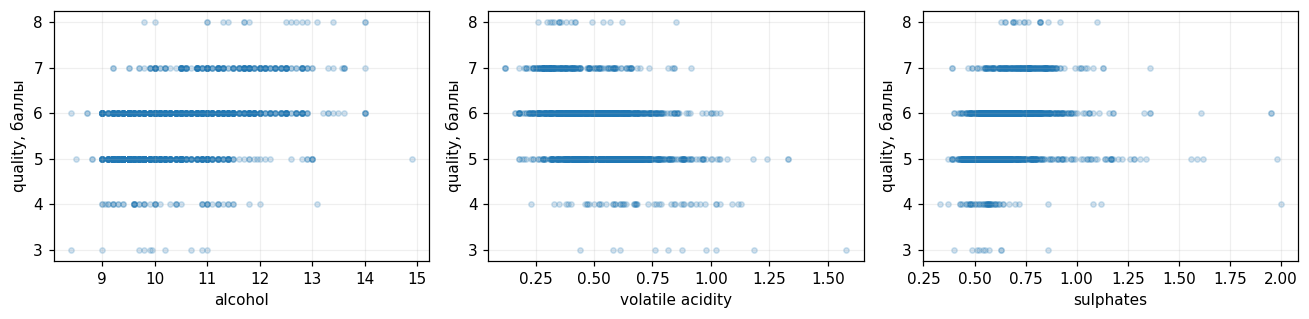

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, feature in zip(axes, ['alcohol', 'volatile acidity', 'sulphates']):
    ax.scatter(data[feature], data['quality'], alpha=0.2, s=12)
    ax.set(xlabel=feature, ylabel='quality, баллы')
show_plot()

**Вывод по EDA.** В наблюдениях более высокое содержание алкоголя связано с более высоким
качеством, а высокая летучая кислотность — с более низким. Связь с сульфатами положительная.
Однако точки заметно разбросаны: одного признака недостаточно для точного прогноза.
Плотность, содержание алкоголя и кислотности связаны между собой; это важно при трактовке
коэффициентов. Сохраняем все признаки и сравниваем линейную модель с ансамблями деревьев.
Эти связи не доказывают, что изменение состава само по себе вызывает изменение качества.

## 3. Разделение на train и test

Откладываем **20% групп** для финального теста и оставляем около 80% строк для обучения.
Группируем по всем входным признакам, без `quality`: одинаковые измерения должны целиком
попадать в одну часть. Обычное случайное разбиение могло бы распределить копии по train и test
и завысить качество. Данных о времени и партиях вина нет, поэтому такую независимость проверить нельзя.

In [10]:
X = data.drop(columns='quality')
y = data['quality']
groups = pd.util.hash_pandas_object(X, index=False).astype(str)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
train_groups = groups.iloc[train_idx]

### Проверка разбиения

Сравним размеры частей и распределения target, проверим отсутствие пересечения групп.
Из-за размеров групп доля строк может немного отличаться от заданной доли групп.
Разбиение не стратифицировано: для редких оценок доли могут заметно колебаться.

In [11]:
overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
assert not overlap
print(f'Train: {len(X_train)} строк ({len(X_train) / len(data):.1%})')
print(f'Test: {len(X_test)} строк ({len(X_test) / len(data):.1%})')
print('Общих групп измерений:', len(overlap))
distribution = pd.DataFrame({
    'train_share': y_train.value_counts(normalize=True),
    'test_share': y_test.value_counts(normalize=True),
}).sort_index().fillna(0)
display(distribution)

Train: 1279 строк (80.0%)
Test: 320 строк (20.0%)
Общих групп измерений: 0


,train_share,test_share
quality,,
3,0.0063,0.0063
4,0.0360,0.0219
5,0.4300,0.4094
6,0.3933,0.4219
7,0.1235,0.1281
8,0.0109,0.0125


**Вывод.** Части не содержат одинаковых наборов измерений. Размер train достаточен для
обучения, а test из 320 строк позволяет получить отдельную итоговую оценку.
Если многократно менять модели по test-метрике, мы фактически подстроимся под этот test.
Поэтому далее используем только train и кросс-валидацию; test-метрики посмотрим после фиксации выбора.

## 4. Метрики и кросс-валидация

$$MAE = \frac{1}{n}\sum_i |y_i-\hat y_i|,\qquad
RMSE = \sqrt{\frac{1}{n}\sum_i (y_i-\hat y_i)^2}.$$

**MAE** — средняя абсолютная ошибка в баллах качества. **RMSE** также измеряется в баллах,
но сильнее реагирует на крупные ошибки из-за возведения в квадрат.
Для ошибок 0 и 2 получим MAE=1 и RMSE≈1.414. Несколько больших промахов могут заметно
разнести метрики; RMSE всегда не меньше MAE.

Создаём одни и те же **5 групповых фолдов** внутри train для всех моделей.
Копии измерений также не должны пересекать границу фолдов.

In [12]:
cv = GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X_train, y_train, train_groups))
for fit_idx, valid_idx in folds:
    assert set(train_groups.iloc[fit_idx]).isdisjoint(train_groups.iloc[valid_idx])

scoring = {'RMSE': 'neg_root_mean_squared_error', 'MAE': 'neg_mean_absolute_error'}
cv_rows = []
print('Созданы 5 одинаковых для всех моделей фолдов; пересечений групп нет.')

Созданы 5 одинаковых для всех моделей фолдов; пересечений групп нет.


Небольшая функция собирает результаты CV в одну строку таблицы.
В scikit-learn ошибки возвращаются со знаком минус, потому что scorer максимизируется.
Стандартное отклонение между фолдами характеризует разброс оценок, а не доверительный интервал.

In [13]:
def cv_summary(name, scores):
    return {
        'model': name,
        'CV_RMSE': -scores['test_RMSE'].mean(),
        'CV_RMSE_std': scores['test_RMSE'].std(),
        'CV_MAE': -scores['test_MAE'].mean(),
    }

## 5. Baseline

Предсказываем одну константу — **среднее `quality` на train**.
Минимизация RMSE эквивалентна минимизации MSE, а производная
$\sum_i(y_i-c)^2$ по $c$ равна нулю при $c=\overline y$.
Для MAE оптимальна медиана, но главная метрика этой работы — RMSE.

In [14]:
baseline = DummyRegressor(strategy='mean')
baseline_scores = cross_validate(baseline, X_train, y_train, cv=folds, scoring=scoring)
baseline.fit(X_train, y_train)
cv_rows.append(cv_summary('Baseline', baseline_scores))
print(f'Константа baseline: {y_train.mean():.4f}')
display(pd.DataFrame([cv_rows[-1]]))

Константа baseline: 5.6247


,model,CV_RMSE,CV_RMSE_std,CV_MAE
0,Baseline,0.8111,0.0325,0.6878


**Вывод.** Это точка отсчёта: модель должна извлекать из признаков больше информации,
чем прогноз одной средней оценкой. В каждом CV-фолде константа вычисляется только по
обучающей части этого фолда. Финальный baseline будет проверен на общем test вместе с моделями.

## 6. Линейная регрессия

Используем `StandardScaler → LinearRegression` в Pipeline. Масштабирование обучается
заново внутри каждого фолда, поэтому валидационные статистики не утекают в обучение.
Для обычной линейной регрессии стандартизация почти не меняет прогнозы, но делает веса сопоставимыми.

In [15]:
linear = make_pipeline(StandardScaler(), LinearRegression())
linear_scores = cross_validate(linear, X_train, y_train, cv=folds, scoring=scoring)
linear.fit(X_train, y_train)
cv_rows.append(cv_summary('Linear Regression', linear_scores))
display(pd.DataFrame([cv_rows[-1]]))

,model,CV_RMSE,CV_RMSE_std,CV_MAE
0,Linear Regression,0.6624,0.0263,0.5103


**Вывод.** Линейная модель учитывает признаки совместно и улучшает CV-результат baseline.
Но она описывает аддитивную линейную зависимость и не может сама учесть сложные пороги
и взаимодействия. Коэффициенты разберём отдельно после сравнения качества.

## 7. Random Forest Regressor

Случайный лес усредняет прогнозы деревьев на bootstrap-подвыборках.
Оставляем 400 деревьев, подбираем `max_features ∈ {0.8, 1.0}` и
`min_samples_leaf ∈ {1, 2}`. Всего 4 кандидата × 5 одинаковых CV-фолдов.
Масштабирование для деревьев не требуется.

In [16]:
forest_search = GridSearchCV(
    RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE, n_jobs=1),
    param_grid={'max_features': [0.8, 1.0], 'min_samples_leaf': [1, 2]},
    scoring=scoring, refit='RMSE', cv=folds, n_jobs=1, error_score='raise',
)
forest_search.fit(X_train, y_train)
forest = forest_search.best_estimator_
print('Лучшие параметры:', forest_search.best_params_)
print(f'Лучший CV RMSE: {-forest_search.best_score_:.4f}')

Лучшие параметры: {'max_features': 0.8, 'min_samples_leaf': 1}
Лучший CV RMSE: 0.6351


In [17]:
best = forest_search.best_index_
cv_rows.append({
    'model': 'Random Forest',
    'CV_RMSE': -forest_search.best_score_,
    'CV_RMSE_std': forest_search.cv_results_['std_test_RMSE'][best],
    'CV_MAE': -forest_search.cv_results_['mean_test_MAE'][best],
})
display(pd.DataFrame(forest_search.cv_results_)[['params', 'mean_test_RMSE', 'rank_test_RMSE']])

,params,mean_test_RMSE,rank_test_RMSE
0,"{'max_features': 0.8, 'min_samples_leaf': 1}",-0.6351,1
1,"{'max_features': 0.8, 'min_samples_leaf': 2}",-0.6355,2
2,"{'max_features': 1.0, 'min_samples_leaf': 1}",-0.6386,4
3,"{'max_features': 1.0, 'min_samples_leaf': 2}",-0.6367,3


**Вывод.** Лес может учитывать нелинейные зависимости и взаимодействия признаков.
Его CV-ошибка ниже, чем у линейной модели. Это преимущество пока относится к CV,
а не является утверждением о любом будущем наборе данных.

## 8. Gradient Boosting Regressor

Бустинг последовательно добавляет деревья, исправляющие ошибки текущей композиции.
При `learning_rate=0.05` сравним `n_estimators ∈ {300, 600}` и `max_depth ∈ {2, 3}`.
Здесь тоже 4 кандидата × те же 5 CV-фолдов. Test не используется для подбора.

In [18]:
boosting_search = GridSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE, learning_rate=0.05),
    param_grid={'n_estimators': [300, 600], 'max_depth': [2, 3]},
    scoring=scoring, refit='RMSE', cv=folds, n_jobs=1, error_score='raise',
)
boosting_search.fit(X_train, y_train)
boosting = boosting_search.best_estimator_
print('Лучшие параметры:', boosting_search.best_params_)
print(f'Лучший CV RMSE: {-boosting_search.best_score_:.4f}')

Лучшие параметры: {'max_depth': 2, 'n_estimators': 300}
Лучший CV RMSE: 0.6420


In [19]:
best = boosting_search.best_index_
cv_rows.append({
    'model': 'Gradient Boosting',
    'CV_RMSE': -boosting_search.best_score_,
    'CV_RMSE_std': boosting_search.cv_results_['std_test_RMSE'][best],
    'CV_MAE': -boosting_search.cv_results_['mean_test_MAE'][best],
})
display(pd.DataFrame(boosting_search.cv_results_)[['params', 'mean_test_RMSE', 'rank_test_RMSE']])

,params,mean_test_RMSE,rank_test_RMSE
0,"{'max_depth': 2, 'n_estimators': 300}",-0.6420,1
1,"{'max_depth': 2, 'n_estimators': 600}",-0.6579,3
2,"{'max_depth': 3, 'n_estimators': 300}",-0.6521,2
3,"{'max_depth': 3, 'n_estimators': 600}",-0.6671,4


**Вывод.** Бустинг также улучшает CV-качество относительно линейной модели, но в этой
сетке не превосходит лес. Его результат зависит от глубины, числа деревьев и шага обучения;
универсального преимущества перед лесом нет.

## 9. Выбор модели по CV

Сравним средние CV-ошибки и **зафиксируем победителя до вычисления test-метрик**.
GridSearchCV уже переобучил лучший вариант каждого ансамбля на всём train.

In [20]:
validation = pd.DataFrame(cv_rows).set_index('model')
winner = validation['CV_RMSE'].idxmin()
models = {'Baseline': baseline, 'Linear Regression': linear,
          'Random Forest': forest, 'Gradient Boosting': boosting}
display(validation)
print('Выбранная по CV модель:', winner)

,CV_RMSE,CV_RMSE_std,CV_MAE
model,,,
Baseline,0.8111,0.0325,0.6878
Linear Regression,0.6624,0.0263,0.5103
Random Forest,0.6351,0.0299,0.4815
Gradient Boosting,0.6420,0.0296,0.4898


Выбранная по CV модель: Random Forest


## 10. Финальная проверка на едином test

Теперь получаем предсказания всех зафиксированных моделей на одной и той же тестовой части.
Главные столбцы итоговой таблицы — RMSE и MAE. Добавим train RMSE для проверки переобучения
и CV RMSE для сопоставления. Модель по test-таблице не перевыбираем и параметры не меняем.

In [21]:
predictions = {}
test_rows = []
for name, model in models.items():
    predictions[name] = model.predict(X_test)
    test_rows.append({
        'model': name,
        'RMSE': root_mean_squared_error(y_test, predictions[name]),
        'MAE': mean_absolute_error(y_test, predictions[name]),
        'train_RMSE': root_mean_squared_error(y_train, model.predict(X_train)),
    })
metrics = pd.DataFrame(test_rows).set_index('model').join(validation)
display(metrics)

,RMSE,MAE,train_RMSE,CV_RMSE,CV_RMSE_std,CV_MAE
model,,,,,,
Baseline,0.7955,0.6719,0.8103,0.8111,0.0325,0.6878
Linear Regression,0.6426,0.4997,0.6473,0.6624,0.0263,0.5103
Random Forest,0.6454,0.4999,0.2080,0.6351,0.0299,0.4815
Gradient Boosting,0.6493,0.5057,0.5334,0.6420,0.0296,0.4898


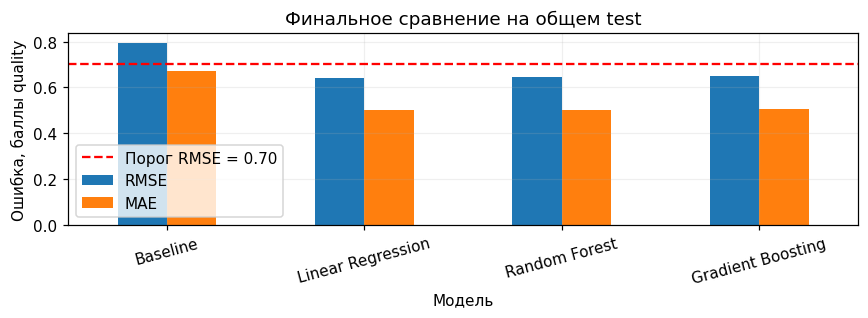

In [22]:
metrics[['RMSE', 'MAE']].plot.bar(figsize=(8, 3), rot=15)
plt.axhline(0.70, color='red', linestyle='--', label='Порог RMSE = 0.70')
plt.ylabel('Ошибка, баллы quality')
plt.xlabel('Модель')
plt.title('Финальное сравнение на общем test')
plt.legend()
show_plot()

In [23]:
test_leader = metrics['RMSE'].idxmin()
gain = 1 - metrics.loc[winner, 'RMSE'] / metrics.loc['Baseline', 'RMSE']
print(f'{winner}: test RMSE={metrics.loc[winner, "RMSE"]:.4f}, MAE={metrics.loc[winner, "MAE"]:.4f}')
print(f'Снижение RMSE относительно baseline: {gain:.1%}')
print('Минимальный test RMSE в таблице у:', test_leader)
print('Локальный порог RMSE < 0.70 пройден:', metrics.loc[winner, 'RMSE'] < 0.70)

Random Forest: test RMSE=0.6454, MAE=0.4999
Снижение RMSE относительно baseline: 18.9%
Минимальный test RMSE в таблице у: Linear Regression
Локальный порог RMSE < 0.70 пройден: True


**Вывод по сравнению.** Все три модели превзошли baseline. Лес выбран по CV, но на этом
test линейная модель немного точнее: различие RMSE около 0.0028 балла. Ранжирование
зависит от выборки; такой небольшой разрыв не доказывает устойчивого превосходства.
У леса train RMSE значительно ниже test RMSE — он заметно подстраивается под train.
У линейной модели ошибки train и test близки. Ансамбли лучше на CV благодаря способности
учитывать нелинейность, однако более сложная модель не обязана выигрывать на каждом test.

Локальный порог пройден. Скрытая выборка преподавателя недоступна, поэтому её результат
заранее неизвестен. Прогнозы не округлялись и не обрезались.

## 11. Коэффициенты и важность признаков

### 11.1. Линейная регрессия

После StandardScaler коэффициент показывает изменение прогноза при увеличении признака
на одно **train-стандартное отклонение**, когда остальные признаки фиксированы.
Сравнивать по модулю такие веса корректнее, чем веса величин в разных исходных масштабах.

,coefficient
alcohol,0.3192
volatile acidity,-0.1661
sulphates,0.1619
total sulfur dioxide,-0.1019
chlorides,-0.0845
pH,-0.0752
free sulfur dioxide,0.0446
citric acid,-0.0244
fixed acidity,0.0207
density,-0.0179


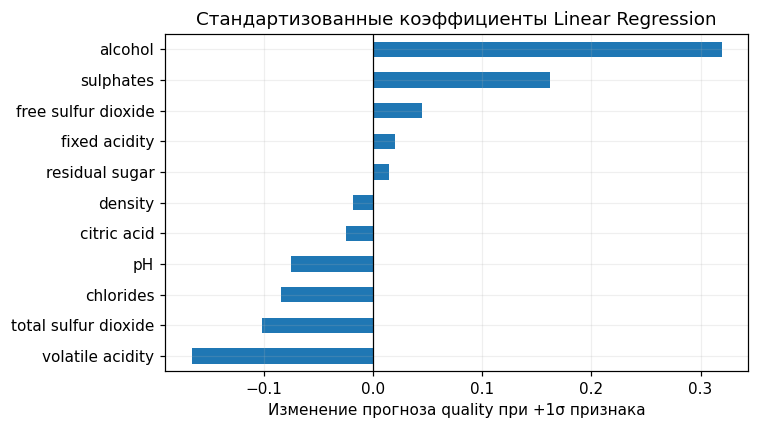

In [24]:
coefficients = pd.Series(linear.named_steps['linearregression'].coef_, index=X.columns)
display(coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).to_frame('coefficient'))
coefficients.sort_values().plot.barh(figsize=(7, 4))
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Изменение прогноза quality при +1σ признака')
plt.title('Стандартизованные коэффициенты Linear Regression')
show_plot()

**Вывод.** Среди наиболее сильных условных линейных связей — alcohol, volatile acidity
и sulphates. Алкоголь связан с ростом прогноза, летучая кислотность — со снижением.
Это согласуется с EDA. При связанных признаках коэффициент отдельной переменной
может меняться из-за присутствия остальных — это не изолированный причинный эффект.

### 11.2. Random Forest и Gradient Boosting

Для деревьев используем `feature_importances_` — нормированное уменьшение impurity (MDI)
по разбиениям обученных деревьев. Важность не показывает знак зависимости.

,Random Forest,Gradient Boosting
alcohol,0.2823,0.4617
sulphates,0.1469,0.1924
volatile acidity,0.1084,0.1267
total sulfur dioxide,0.0754,0.0532
chlorides,0.0626,0.0217
pH,0.0604,0.0340
density,0.0589,0.0296
residual sugar,0.0560,0.0232
fixed acidity,0.0550,0.0315
citric acid,0.0484,0.0149


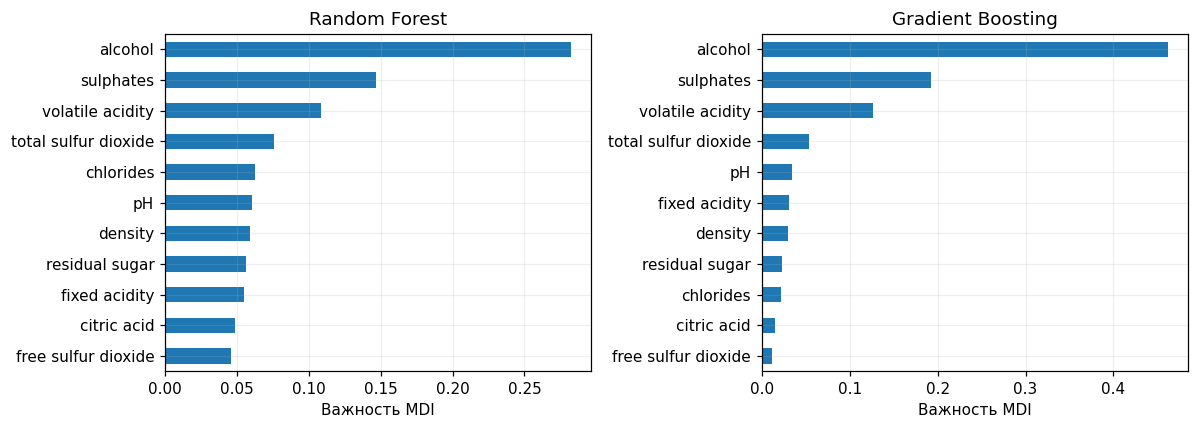

In [25]:
importances = pd.DataFrame({
    'Random Forest': forest.feature_importances_,
    'Gradient Boosting': boosting.feature_importances_,
}, index=X.columns)
display(importances.sort_values('Random Forest', ascending=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, importances.columns):
    importances[name].sort_values().plot.barh(ax=ax)
    ax.set(title=name, xlabel='Важность MDI')
show_plot()

In [26]:
top_features = {
    'EDA (|корреляция|)': target_correlations.abs().nlargest(3).index.tolist(),
    'Linear Regression': coefficients.abs().nlargest(3).index.tolist(),
    'Random Forest': importances['Random Forest'].nlargest(3).index.tolist(),
    'Gradient Boosting': importances['Gradient Boosting'].nlargest(3).index.tolist(),
}
display(pd.DataFrame(top_features, index=['1-е место', '2-е место', '3-е место']).T)

,1-е место,2-е место,3-е место
EDA (|корреляция|),alcohol,volatile acidity,sulphates
Linear Regression,alcohol,volatile acidity,sulphates
Random Forest,alcohol,sulphates,volatile acidity
Gradient Boosting,alcohol,sulphates,volatile acidity


**Вывод.** В обоих ансамблях среди лидеров — alcohol, sulphates и volatile acidity;
это согласуется с линейной моделью и наблюдениями EDA. Порядок может различаться:
корреляция измеряет отдельную линейную связь, коэффициент — условную линейную связь,
а MDI учитывает пороги и взаимодействия. Коррелирующие признаки могут делить важность.

**Можно ли сделать причинный вывод?** Нет: это наблюдательные данные, возможны смешивающие
факторы и неучтённые свойства вина. Высокая важность alcohol не доказывает, что добавление
алкоголя повысит качество. Кроме того, MDI может предпочитать признаки с большим числом
возможных порогов. Для причинных утверждений нужен отдельный эксперимент или причинный дизайн.

## 12. Анализ ошибок выбранной модели

Анализируем выбранный по CV лес. Остаток `quality − prediction` положителен при недооценке
качества. Это финальная диагностика: после неё не меняем модель по результатам test.

In [27]:
errors = X_test.copy()
errors['quality'] = y_test
errors['prediction'] = predictions[winner]
errors['residual'] = errors['quality'] - errors['prediction']
errors['absolute_error'] = errors['residual'].abs()

### 12.1. Распределение остатков и истинные/предсказанные оценки

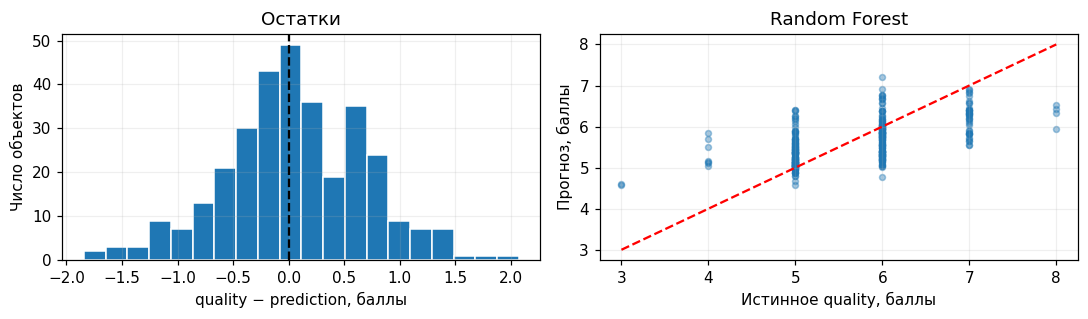

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(errors['residual'], bins=20, edgecolor='white')
axes[0].axvline(0, color='black', linestyle='--')
axes[0].set(xlabel='quality − prediction, баллы', ylabel='Число объектов', title='Остатки')
axes[1].scatter(y_test, errors['prediction'], alpha=0.4, s=15)
axes[1].plot([3, 8], [3, 8], '--', color='red')
axes[1].set(xlabel='Истинное quality, баллы', ylabel='Прогноз, баллы', title=winner)
show_plot()

**Вывод.** Есть ошибки обоих знаков. Прогнозы более сосредоточены около средних оценок,
чем истинные значения: низкое качество модель склонна завышать, а высокое — занижать.
Проверим это численно по группам quality.

### 12.2. Качество прогноза для разных значений quality

In [29]:
group_rows = []
for quality, group in errors.groupby('quality'):
    group_rows.append({
        'quality': quality, 'n_train': int((y_train == quality).sum()), 'n_test': len(group),
        'mean_prediction': group['prediction'].mean(),
        'MAE': group['absolute_error'].mean(),
        'RMSE': root_mean_squared_error(group['quality'], group['prediction']),
    })
errors_by_quality = pd.DataFrame(group_rows).set_index('quality')
display(errors_by_quality)

,n_train,n_test,mean_prediction,MAE,RMSE
quality,,,,,
3,8,2,4.5938,1.5938,1.5938
4,46,7,5.3536,1.3536,1.3857
5,550,131,5.3465,0.3769,0.5081
6,503,135,5.7370,0.4332,0.5259
7,158,41,6.2040,0.7960,0.8810
8,14,4,6.2969,1.7031,1.7177


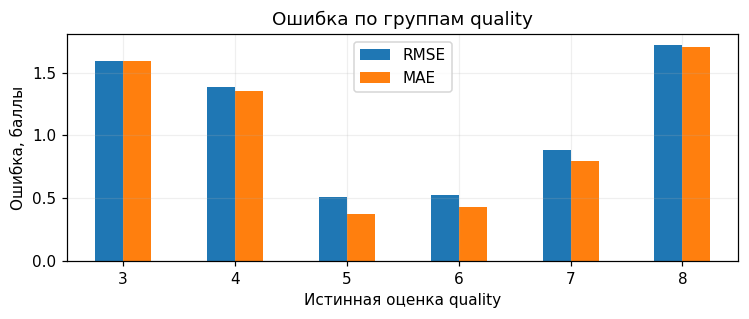

In [30]:
errors_by_quality[['RMSE', 'MAE']].plot.bar(figsize=(7, 3), rot=0)
plt.xlabel('Истинная оценка quality')
plt.ylabel('Ошибка, баллы')
plt.title('Ошибка по группам quality')
show_plot()

**Вывод.** На частых оценках 5 и 6 модель точнее, чем на крайних.
У редких оценок мало обучающих примеров; при квадратичной функции потерь прогноз
стремится к условному среднему. Для групп с малым `n_test` сами метрики нестабильны,
поэтому их нельзя трактовать без указания размеров групп.

### 12.3. Объекты с самыми крупными ошибками

In [31]:
worst_errors = errors.sort_values('absolute_error', ascending=False).head(10)
display(worst_errors)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,prediction,residual,absolute_error
1403,7.2,0.330,0.33,1.70,0.061,3.0,13.0,0.9960,3.23,1.10,10.0,8,5.9300,2.0700,2.0700
1484,6.8,0.910,0.06,2.00,0.060,4.0,11.0,0.9959,3.53,0.64,10.9,4,5.8425,-1.8425,1.8425
876,7.1,0.470,0.00,2.20,0.067,7.0,14.0,0.9952,3.40,0.58,10.9,4,5.6875,-1.6875,1.6875
1449,7.2,0.380,0.31,2.00,0.056,15.0,29.0,0.9947,3.23,0.76,11.3,8,6.3200,1.6800,1.6800
899,8.3,1.020,0.02,3.40,0.084,6.0,11.0,0.9989,3.48,0.49,11.0,3,4.6100,-1.6100,1.6100
455,11.3,0.620,0.67,5.20,0.086,6.0,19.0,0.9988,3.22,0.69,13.4,8,6.4200,1.5800,1.5800
690,7.4,1.185,0.00,4.25,0.097,5.0,14.0,0.9966,3.63,0.54,10.7,3,4.5775,-1.5775,1.5775
151,9.2,0.520,1.00,3.40,0.610,32.0,69.0,0.9996,2.74,2.00,9.4,4,5.4975,-1.4975,1.4975
1269,5.5,0.490,0.03,1.80,0.044,28.0,87.0,0.9908,3.50,0.82,14.0,8,6.5175,1.4825,1.4825
1089,11.6,0.410,0.54,1.50,0.095,22.0,41.0,0.9973,3.02,0.76,9.9,7,5.5425,1.4575,1.4575


Для трёх самых больших ошибок найдём пять ближайших объектов **из train** в пространстве
стандартизованных признаков. Это помогает проверить, бывают ли у похожих измерений другие
экспертные оценки. Соседи используются только для объяснения, не для донастройки модели.

In [32]:
neighbor_scaler = StandardScaler().fit(X_train)
train_scaled = neighbor_scaler.transform(X_train)
example_rows = []
for row_id, row in worst_errors.head(3).iterrows():
    sample_scaled = neighbor_scaler.transform(X_test.loc[[row_id]])
    distances = np.linalg.norm(train_scaled - sample_scaled, axis=1)
    nearest = np.argsort(distances)[:5]
    example_rows.append({
        'row_id': row_id, 'quality': row['quality'], 'prediction': row['prediction'],
        'absolute_error': row['absolute_error'], 'nearby_train_quality': y_train.iloc[nearest].tolist(),
    })
display(pd.DataFrame(example_rows))

,row_id,quality,prediction,absolute_error,nearby_train_quality
0,1403,8.0,5.9300,2.0700,"[5, 5, 6, 5, 7]"
1,1484,4.0,5.8425,1.8425,"[6, 6, 6, 6, 6]"
2,876,4.0,5.6875,1.6875,"[6, 6, 6, 6, 6]"


In [33]:
for example in example_rows:
    print(f'Строка {example["row_id"]}: quality={example["quality"]:.0f}, '
          f'прогноз={example["prediction"]:.2f}, ошибка={example["absolute_error"]:.2f}; '
          f'оценки соседей train: {example["nearby_train_quality"]}.')

Строка 1403: quality=8, прогноз=5.93, ошибка=2.07; оценки соседей train: [5, 5, 6, 5, 7].
Строка 1484: quality=4, прогноз=5.84, ошибка=1.84; оценки соседей train: [6, 6, 6, 6, 6].
Строка 876: quality=4, прогноз=5.69, ошибка=1.69; оценки соседей train: [6, 6, 6, 6, 6].


**Вывод по примерам.** В таблице видно, что близкие химические измерения могут соответствовать
другим экспертным оценкам. Это возможное объяснение крупных промахов: модель обучается на
похожих примерах с иными ответами. Крайние оценки также слабо представлены, а свойства вроде
сорта винограда и условий производства не включены в данные. Экспертная оценка может быть шумной.
Это гипотезы о причинах ошибок, а не доказанные причины для конкретной бутылки.

## 13. Итог

- Выполнен EDA исходного датасета; показаны пропуски, дубликаты, распределения и корреляции.
- Подготовлены train/test около 80/20 без пересечения одинаковых измерений.
- Baseline и три модели обучены и сравнены в одинаковых условиях; параметры выбирались по CV.
- Разобраны стандартизованные коэффициенты, важность признаков и ошибки по quality.

Лес лучше по CV, а на этом test линейная регрессия чуть точнее. Разница мала и не является
основанием объявлять один алгоритм универсально лучшим. Выбранный по CV лес сохраняем как
итоговый результат выбора, не подстраивая решение под test.

In [34]:
display(metrics[['RMSE', 'MAE', 'CV_RMSE']])
print('Выбрано по CV:', winner)
print(f'Итоговый test RMSE: {metrics.loc[winner, "RMSE"]:.4f}')
print(f'Итоговый test MAE: {metrics.loc[winner, "MAE"]:.4f}')

,RMSE,MAE,CV_RMSE
model,,,
Baseline,0.7955,0.6719,0.8111
Linear Regression,0.6426,0.4997,0.6624
Random Forest,0.6454,0.4999,0.6351
Gradient Boosting,0.6493,0.5057,0.6420


Выбрано по CV: Random Forest
Итоговый test RMSE: 0.6454
Итоговый test MAE: 0.4999


**Ограничения.** Исследовано только красное Vinho Verde. Перенос на белое вино, другие
регионы и партии не проверялся. Группировка защищает от одинаковых измерений, но не от
неизвестной зависимости между партиями. Крайние оценки редки, test ограничен по размеру.
CV победителя несколько оптимистичен из-за выбора параметров; отдельный test служит
финальной проверкой. Результат скрытого теста преподавателя заранее неизвестен.

## 14. Как запустить

Нужны только `lab01.ipynb` и `winequality-red.csv` в одной папке.
На этом компьютере библиотеки уже установлены:

```powershell
cd C:\ML\lab1
.\.venv\Scripts\python.exe -m jupyterlab lab01.ipynb
```

В JupyterLab: **Kernel → Restart Kernel and Run All Cells**. После выполнения — **Ctrl+S**.
Все таблицы и графики сохраняются внутри ноутбука, дополнительные файлы не создаются.
Уже выполненный ноутбук можно просматривать без пересчёта.

На другом компьютере с Python 3.12+ сначала установите библиотеки:

```powershell
python -m pip install numpy==2.4.4 pandas==3.0.1 matplotlib==3.10.9 scikit-learn==1.8.0 jupyterlab==4.5.6
python -m jupyterlab lab01.ipynb
```

Интернет нужен для установки библиотек; сам эксперимент использует локальный CSV.